# Network Anomaly Detection with Unsupervised Learning
**Supplementary cybersecurity experiment — independent of PRIVATE SHIELD**

**Question:** Can unsupervised detectors identify unusual traffic patterns when trained on normal traffic only?

This notebook uses simulated flow features, not real network captures. Labels are used only for evaluation. Results demonstrate a workflow, not real-world intrusion detection performance or the original project's results. CPU is sufficient.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.decomposition import PCA
from time import perf_counter
rng = np.random.default_rng(42)


## 1. Generate simulated network flow data
Six illustrative features represent traffic volume, connection duration and protocol behavior. Two anomalous patterns are generated: high-rate traffic and repeated short connections. Some overlap with normal traffic is intentional.

In [2]:
features = ['packets_per_sec','bytes_per_sec','duration_sec','syn_ratio','connections_per_sec','mean_packet_bytes']
def flows(n, center, spread):
    x = rng.lognormal(np.log(center), spread, size=(n,6))
    x[:,3] = np.clip(x[:,3],0,1)
    return pd.DataFrame(x, columns=features)
normal_center = [40,18000,12,.08,3,450]
spread = [.65,.8,.7,.65,.7,.4]
train = flows(1800, normal_center, spread)
normal = flows(600, normal_center, spread)
a = flows(100,[120,50000,5,.45,12,420],spread)
b = flows(100,[60,12000,2,.25,22,180],spread)
test = pd.concat([normal,a,b],ignore_index=True)
y = np.r_[np.zeros(len(normal),dtype=int),np.ones(len(a)+len(b),dtype=int)]
order = rng.permutation(len(test)); test=test.iloc[order].reset_index(drop=True); y=y[order]
print('Normal training samples:',len(train),' | Test samples:',len(test),' | Test anomalies:',y.sum())
display(train.head())


Normal training samples: 1800  | Test samples: 800  | Test anomalies: 200


,packets_per_sec,bytes_per_sec,duration_sec,syn_ratio,connections_per_sec,mean_packet_bytes
0,48.761719,7833.304667,20.291914,0.147436,0.765587,267.301111
1,43.465856,13976.504699,11.859697,0.045950,5.552181,614.226871
2,41.754173,44352.306913,16.645888,0.045763,3.883504,306.646170
3,70.800931,17295.234984,10.543431,0.051389,7.059620,423.026908
4,30.279362,13580.907111,17.418330,0.101450,4.004926,534.630569


## 2. Visualize the traffic
Colors use known synthetic labels for explanation only. Models do not see these labels during training.

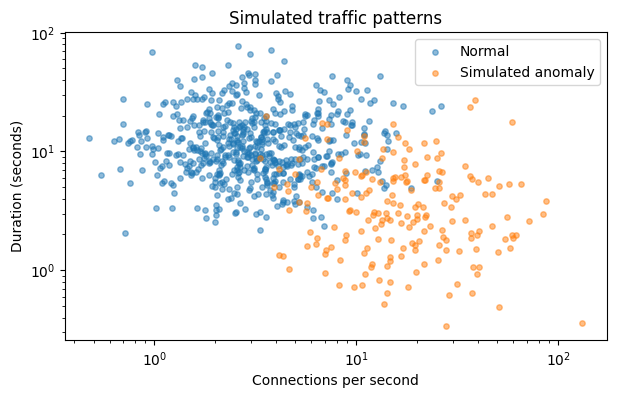

In [3]:
fig, ax = plt.subplots(figsize=(7,4))
for label,name in [(0,'Normal'),(1,'Simulated anomaly')]:
    ax.scatter(test.loc[y==label,'connections_per_sec'],test.loc[y==label,'duration_sec'],s=15,alpha=.5,label=name)
ax.set(xscale='log',yscale='log',xlabel='Connections per second',ylabel='Duration (seconds)',title='Simulated traffic patterns'); ax.legend(); plt.show()


## 3. Train the models
Standardization is fitted only on training data. All detectors receive the same normal-only training data. Fixed illustrative hyperparameters are chosen before test evaluation; no test-based tuning is performed. LOF uses novelty mode to predict unseen samples.

In [4]:
scaler=StandardScaler()
X_train=scaler.fit_transform(np.log1p(train))
X_test=scaler.transform(np.log1p(test))
models={
    'Isolation Forest':IsolationForest(n_estimators=100,contamination=.05,random_state=42,n_jobs=2),
    'Local Outlier Factor':LocalOutlierFactor(n_neighbors=20,novelty=True,contamination=.05),
    'One-Class SVM':OneClassSVM(kernel='rbf',gamma='scale',nu=.05)
}
results=[]; predictions={}; scores={}
for name,model in models.items():
    start=perf_counter(); model.fit(X_train); elapsed=perf_counter()-start
    pred=(model.predict(X_test)==-1).astype(int)
    score=-model.decision_function(X_test)
    predictions[name]=pred; scores[name]=score
    results.append({'Model':name,'Accuracy':accuracy_score(y,pred),'Precision':precision_score(y,pred,zero_division=0),'Recall':recall_score(y,pred),'F1':f1_score(y,pred),'ROC AUC':roc_auc_score(y,score),'Fit seconds':elapsed})
results=pd.DataFrame(results).set_index('Model')
display(results.round(3))


,Accuracy,Precision,Recall,F1,ROC AUC,Fit seconds
Model,,,,,,
Isolation Forest,0.949,0.853,0.96,0.904,0.991,0.137
Local Outlier Factor,0.950,0.857,0.96,0.906,0.991,0.022
One-Class SVM,0.938,0.815,0.97,0.886,0.990,0.007


## 4. Compare results
Recall measures the proportion of anomalies detected. Precision measures how many alerts are correct. F1 balances both. ROC AUC evaluates ranking across thresholds.

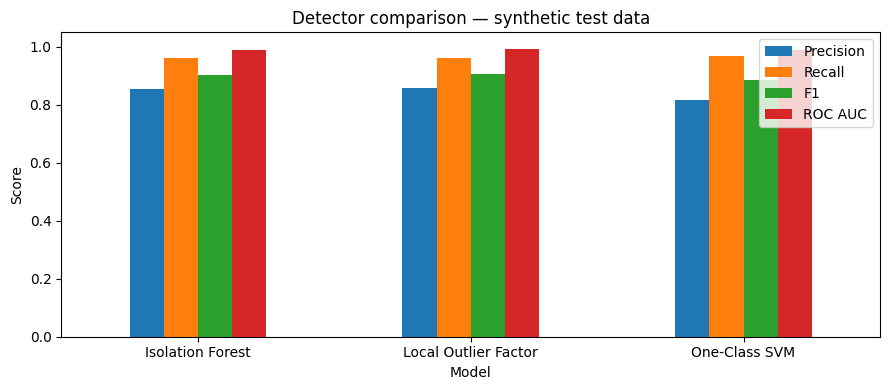

In [5]:
results[['Precision','Recall','F1','ROC AUC']].plot.bar(figsize=(9,4),ylim=(0,1.05),rot=0)
plt.ylabel('Score'); plt.title('Detector comparison — synthetic test data'); plt.tight_layout(); plt.show()


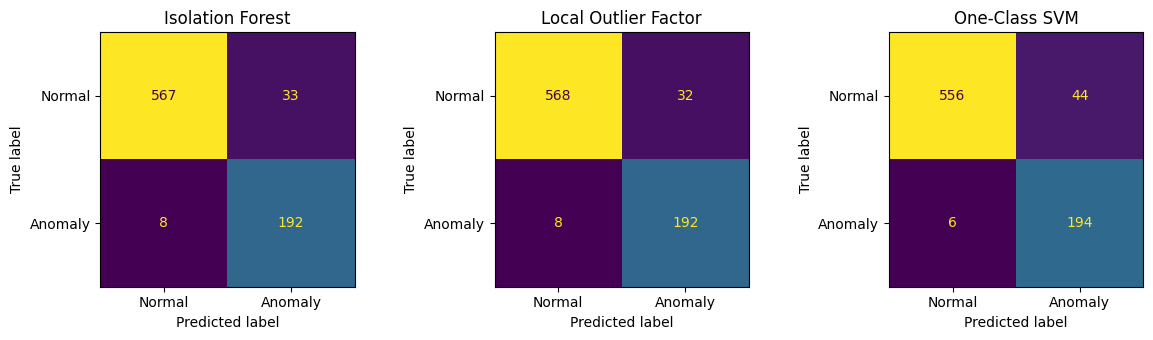

In [6]:
fig,axs=plt.subplots(1,3,figsize=(12,3.5))
for ax,(name,pred) in zip(axs,predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y,pred,labels=[0,1],display_labels=['Normal','Anomaly'],ax=ax,colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()


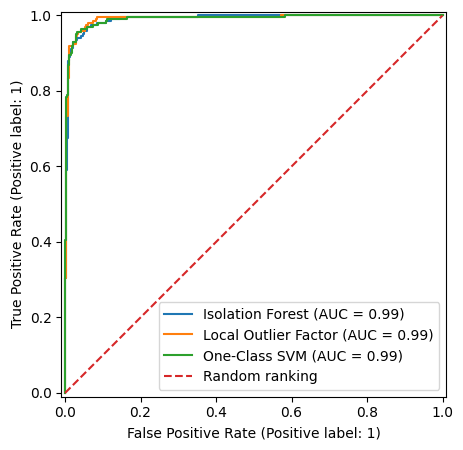

In [7]:
fig,ax=plt.subplots(figsize=(6,5))
for name,score in scores.items():
    RocCurveDisplay.from_predictions(y,score,name=name,ax=ax)
ax.plot([0,1],[0,1],'--',label='Random ranking'); ax.legend(); plt.show()


## 5. Demonstrate predictions on new example flows
Each detector returns an anomaly flag, not an attack category or calibrated probability.

In [8]:
examples=pd.DataFrame([[40,18000,12,.08,3,450],[300,100000,1,.8,40,250],[60,12000,2,.25,22,180]],columns=features,index=['Typical flow','Extreme flow','Short repeated flow'])
output=examples.copy()
for name,model in models.items():
    output[name]=np.where(model.predict(scaler.transform(np.log1p(examples)))==-1,'Anomaly','Normal')
display(output)


,packets_per_sec,bytes_per_sec,duration_sec,syn_ratio,connections_per_sec,mean_packet_bytes,Isolation Forest,Local Outlier Factor,One-Class SVM
Typical flow,40,18000,12,0.08,3,450,Normal,Normal,Normal
Extreme flow,300,100000,1,0.80,40,250,Anomaly,Anomaly,Anomaly
Short repeated flow,60,12000,2,0.25,22,180,Anomaly,Anomaly,Anomaly


In [9]:
results.to_csv('anomaly_detection_results.csv')
best=results['F1'].idxmax()
print(f'Highest observed F1 on this synthetic test: {best} ({results.loc[best,"F1"]:.3f})')
print('This is a descriptive comparison, not independent validation or proof of real-world superiority.')


Highest observed F1 on this synthetic test: Local Outlier Factor (0.906)
This is a descriptive comparison, not independent validation or proof of real-world superiority.


## 6. Conclusion and discussion
- Normal-only training can be useful when attack labels are scarce.
- False positives and missed anomalies matter more than accuracy alone.
- Synthetic traffic makes the experiment lightweight but limits external validity.
- Future work: validate on real network flows with independent capture splits, tune on validation data, and measure robustness under distribution shift.

**Demo script:** “Our main project studies federated intrusion detection. This is a separate exploratory experiment that investigates whether unusual traffic can be identified without labeled attacks. I generated simulated flows, trained three unsupervised algorithms on normal traffic, and compared their detection performance using recall, F1 and confusion matrices. These results are preliminary and do not represent our main research dataset.”
